<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding How The Data Is Distributed**


Estimated time needed: **30** minutes


In this lab, you will work with a cleaned dataset to perform Exploratory Data Analysis (EDA). You will examine the structure of the data, visualize key variables, and analyze trends related to developer experience, tools, job satisfaction, and other important aspects.


## Objectives


In this lab you will perform the following:


- Understand the structure of the dataset.

- Perform summary statistics and data visualization.

- Identify trends in developer experience, tools, job satisfaction, and other key variables.


### Install the required libraries


In [1]:
!pip install pandas
!pip install matplotlib
!pip install seaborn


### Step 1: Import Libraries and Load Data


- Import the `pandas`, `matplotlib.pyplot`, and `seaborn` libraries.


- You will begin with loading the dataset. You can use the pyfetch method if working on JupyterLite. Otherwise, you can use pandas' read_csv() function directly on their local machines or cloud environments.


In [2]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Stack Overflow survey dataset
data_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
df = pd.read_csv(data_url)

# Display the first few rows of the dataset
df.head()


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Step 2: Examine the Structure of the Data


- Display the column names, data types, and summary information to understand the data structure.

- Objective: Gain insights into the dataset's shape and available variables.


In [4]:
## Write your code here
# Examine the structure of the dataset
print('Datset Shape:', df.shape)
print('Dataset columns name:')
print(df.columns.to_list())
print('\nData typed and non-null counts:')
df.info()

Datset Shape: (65437, 114)
Dataset columns name:
['ResponseId', 'MainBranch', 'Age', 'Employment', 'RemoteWork', 'Check', 'CodingActivities', 'EdLevel', 'LearnCode', 'LearnCodeOnline', 'TechDoc', 'YearsCode', 'YearsCodePro', 'DevType', 'OrgSize', 'PurchaseInfluence', 'BuyNewTool', 'BuildvsBuy', 'TechEndorse', 'Country', 'Currency', 'CompTotal', 'LanguageHaveWorkedWith', 'LanguageWantToWorkWith', 'LanguageAdmired', 'DatabaseHaveWorkedWith', 'DatabaseWantToWorkWith', 'DatabaseAdmired', 'PlatformHaveWorkedWith', 'PlatformWantToWorkWith', 'PlatformAdmired', 'WebframeHaveWorkedWith', 'WebframeWantToWorkWith', 'WebframeAdmired', 'EmbeddedHaveWorkedWith', 'EmbeddedWantToWorkWith', 'EmbeddedAdmired', 'MiscTechHaveWorkedWith', 'MiscTechWantToWorkWith', 'MiscTechAdmired', 'ToolsTechHaveWorkedWith', 'ToolsTechWantToWorkWith', 'ToolsTechAdmired', 'NEWCollabToolsHaveWorkedWith', 'NEWCollabToolsWantToWorkWith', 'NEWCollabToolsAdmired', 'OpSysPersonal use', 'OpSysProfessional use', 'OfficeStackAsyncH

### Step 3: Handle Missing Data


- Identify missing values in the dataset.

- Impute or remove missing values as necessary to ensure data completeness.



In [5]:
## Write your code here
# Identify missing values
missing_summary=(df.isna().sum().sort_values(ascending=False).rename('MissingCount'))
print(missing_summary[missing_summary>0].head(20))

#Create a cleaned copy. Impute key categorical fields with their mode.
#Keep mnumeric missing values as NaN and exclude them per analysis,
#rather than creating artificial survey scores.
df_clean=df.copy()
for column in ['Employment','RemoteWork']:
    mode=df_clean[column].mode(dropna=True)
    if not mode.empty:
        df_clean[column]=df_clean[column].fillna(mode.iloc[0])

print('Missing values after categorical imputation:')
print(df_clean[['Employment','RemoteWork']].isna().sum())


AINextMuch less integrated       64289
AINextLess integrated            63082
AINextNo change                  52939
AINextMuch more integrated       51999
EmbeddedAdmired                  48704
EmbeddedWantToWorkWith           47837
EmbeddedHaveWorkedWith           43223
ConvertedCompYearly              42002
AIToolNot interested in Using    41023
AINextMore integrated            41009
Knowledge_9                      37802
Frequency_3                      37727
Knowledge_8                      37679
ProfessionalTech                 37673
Knowledge_7                      37659
Knowledge_6                      37573
Knowledge_5                      37557
Knowledge_2                      37416
Knowledge_4                      37407
Knowledge_3                      37342
Name: MissingCount, dtype: int64
Missing values after categorical imputation:
Employment    0
RemoteWork    0
dtype: int64


### Step 4: Analyze Key Columns


- Examine key columns such as `Employment`, `JobSat` (Job Satisfaction), and `YearsCodePro` (Professional Coding Experience).

- **Instruction**: Calculate the value counts for each column to understand the distribution of responses.



In [6]:
## Write your code here
for column in ['Employment','JobSat','YearsCodePro']:
    print(f'\nValue counts for {column}:')
    print(df_clean[column].value_counts(dropna=False).head(20))


Value counts for Employment:
Employment
Employed, full-time                                                                        39041
Independent contractor, freelancer, or self-employed                                        4846
Student, full-time                                                                          4709
Employed, full-time;Independent contractor, freelancer, or self-employed                    3557
Not employed, but looking for work                                                          2341
Employed, part-time                                                                         1266
Student, full-time;Employed, part-time                                                      1115
Employed, full-time;Student, full-time                                                       897
Employed, full-time;Student, part-time                                                       839
Student, full-time;Not employed, but looking for work                                 

### Step 5: Visualize Job Satisfaction (Focus on JobSat)


- Create a pie chart or KDE plot to visualize the distribution of `JobSat`.

- Provide an interpretation of the plot, highlighting key trends in job satisfaction.


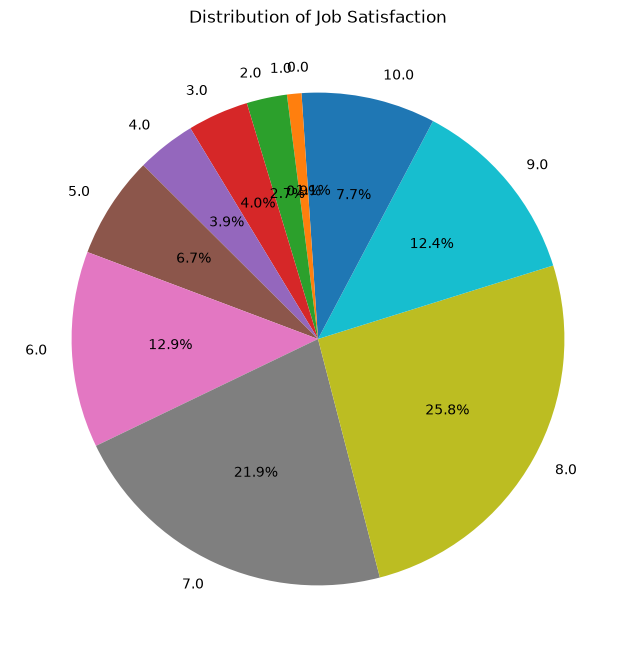

Most frequent JobSat values:
JobSat
8.0     7509
7.0     6379
6.0     3751
9.0     3626
10.0    2251
Name: count, dtype: int64


In [7]:
## Write your code here
# Job satisfaction distribution, excluding missing JobSat responses
job_sat_counts = df_clean['JobSat'].dropna().value_counts().sort_index()
plt.figure(figsize=(8, 8))
plt.pie(job_sat_counts, labels=job_sat_counts.index, autopct='%1.1f%%',
        startangle=90)
plt.title('Distribution of Job Satisfaction')
plt.show()
print('Most frequent JobSat values:')
print(job_sat_counts.sort_values(ascending=False).head())

### Step 6: Programming Languages Analysis


- Compare the frequency of programming languages in `LanguageHaveWorkedWith` and `LanguageWantToWorkWith`.
  
- Visualize the overlap or differences using a Venn diagram or a grouped bar chart.


                         HaveWorkedWith  WantToWorkWith
Rust                               7559           17232
C++                               13827           10873
C#                                16318           12921
Java                              18239           10668
Bash/Shell (all shells)           20412           13744
TypeScript                        23150           20239
SQL                               30682           22400
Python                            30719           25047
HTML/CSS                          31816           20721
JavaScript                        37492           23774


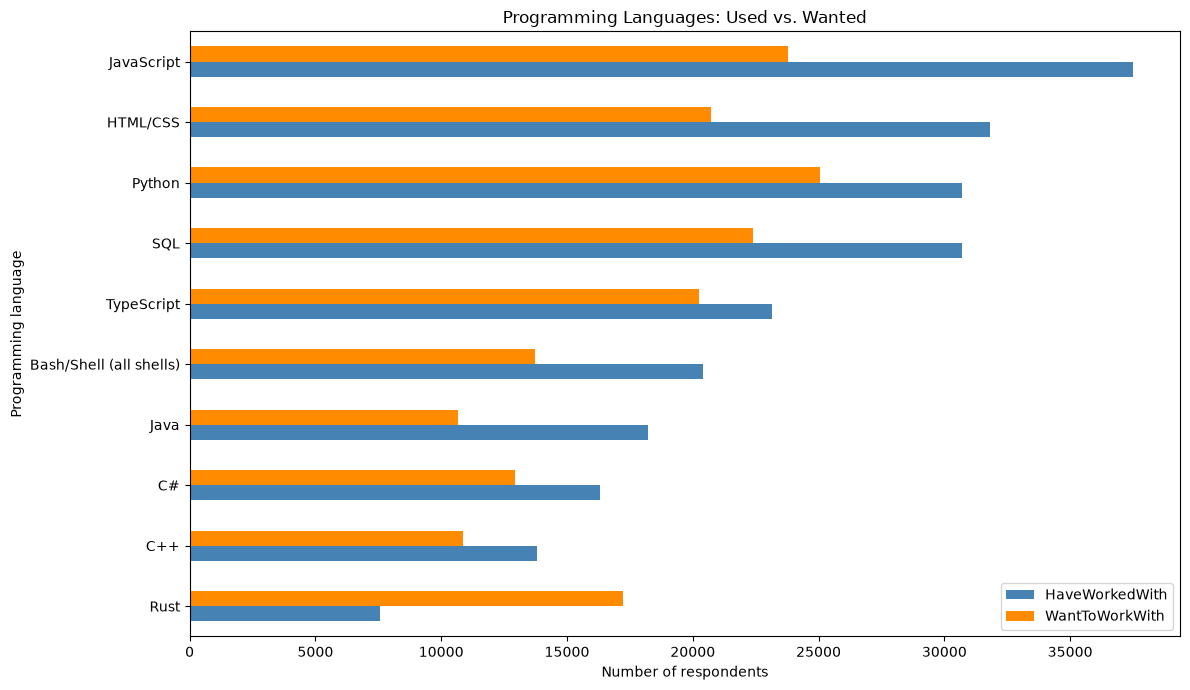

In [8]:
## Write your code here
# Compare languages respondents have worked with and want to work with
def language_counts(column):
    values = (df_clean[column].dropna().astype(str).str.split(';').explode() # Split the semicolon-separated values into individual languages and explode them into separate rows
              .str.strip())
    return values[values.ne('')].value_counts() # values[values.ne('')] filters out any empty strings, and value_counts() counts the occurrences of each unique language

worked_counts = language_counts('LanguageHaveWorkedWith')
want_counts = language_counts('LanguageWantToWorkWith')
language_comparison = pd.concat([worked_counts, want_counts], axis=1,
                               keys=['HaveWorkedWith', 'WantToWorkWith']).fillna(0)# Fill NaN values with 0 for languages that are only in one of the two columns
top_languages = language_comparison.sum(axis=1).nlargest(10).index
language_comparison = language_comparison.loc[top_languages].sort_values(
    'HaveWorkedWith', ascending=True
)
print(language_comparison)

language_comparison.plot(kind='barh', figsize=(12, 7), color=['steelblue', 'darkorange'])
plt.title('Programming Languages: Used vs. Wanted')
plt.xlabel('Number of respondents')
plt.ylabel('Programming language')
plt.tight_layout()
plt.show()

### Step 7: Analyze Remote Work Trends


- Visualize the distribution of RemoteWork by region using a grouped bar chart or heatmap.


RemoteWork                                          Hybrid (some remote, some in-person)  \
Country                                                                                    
Germany                                                                             3098   
India                                                                               2290   
Ukraine                                                                              828   
United Kingdom of Great Britain and Northern Ir...                                  1765   
United States of America                                                            4857   

RemoteWork                                          In-person  Remote  
Country                                                                
Germany                                                   647    1202  
India                                                    1088     853  
Ukraine                                                   111    17

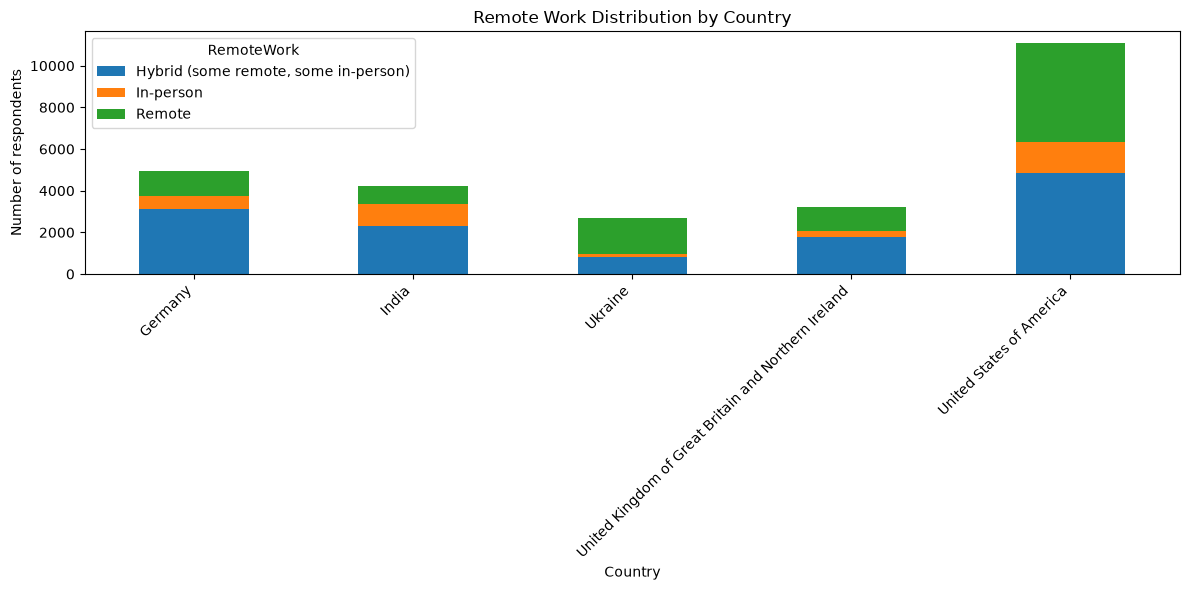

In [14]:
## Write your code here
#Remote work distribution by five countries with most respondents
top_countries=df_clean['Country'].value_counts().head(5).index
remote_region=pd.crosstab(
    df_clean.loc[df_clean['Country'].isin(top_countries),'Country'],
    df_clean.loc[df_clean['Country'].isin(top_countries),'RemoteWork'])

print(remote_region)

remote_region.plot(kind='bar', figsize=(12,6), stacked=True)
plt.title('Remote Work Distribution by Country')
plt.xlabel('Country')
plt.ylabel('Number of respondents')
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.show()

### Step 8: Correlation between Job Satisfaction and Experience


- Analyze the correlation between overall job satisfaction (`JobSat`) and `YearsCodePro`.
  
- Calculate the Pearson or Spearman correlation coefficient.


In [20]:
## Write your code here
%pip install scipy
import scipy as stats
years_pro_numeric = (
    df_clean['YearsCodePro']
      .replace({'Less than 1 year': '0.5', 'More than 50 years': '51'})
      .pipe(pd.to_numeric, errors='coerce')
)
job_sat_numeric = pd.to_numeric(df_clean['JobSat'], errors='coerce')
correlation_data = pd.DataFrame({
    'YearsCodePro': years_pro_numeric,
    'JobSat': job_sat_numeric
}).dropna()

print('Pearson correlation:', correlation_data['YearsCodePro'].corr(
    correlation_data['JobSat'], method='pearson'))
print('Spearman correlation:', correlation_data['YearsCodePro'].corr(
    correlation_data['JobSat'], method='spearman'))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 153.4 MB/s eta 0:00:0000:01
Note: you may need to restart the kernel to use updated packages.
Pearson correlation: 0.10417890170590674
Spearman correlation: 0.1192006740902708


### Step 9: Cross-tabulation Analysis (Employment vs. Education Level)


- Analyze the relationship between employment status (`Employment`) and education level (`EdLevel`).

- **Instruction**: Create a cross-tabulation using `pd.crosstab()` and visualize it with a stacked bar plot if possible.


Employment                                          Employed, full-time  \
EdLevel                                                                   
Associate degree (A.A., A.S., etc.)                               0.591   
Bachelor’s degree (B.A., B.S., B.Eng., etc.)                      0.674   
Master’s degree (M.A., M.S., M.Eng., MBA, etc.)                   0.708   
Primary/elementary school                                         0.140   
Professional degree (JD, MD, Ph.D, Ed.D, etc.)                    0.698   
Secondary school (e.g. American high school, Ge...                0.252   
Some college/university study without earning a...                0.468   
Something else                                                    0.405   

Employment                                          Employed, full-time;Employed, part-time  \
EdLevel                                                                                       
Associate degree (A.A., A.S., etc.)                        

/tmp/ipykernel_421/781685246.py:12: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


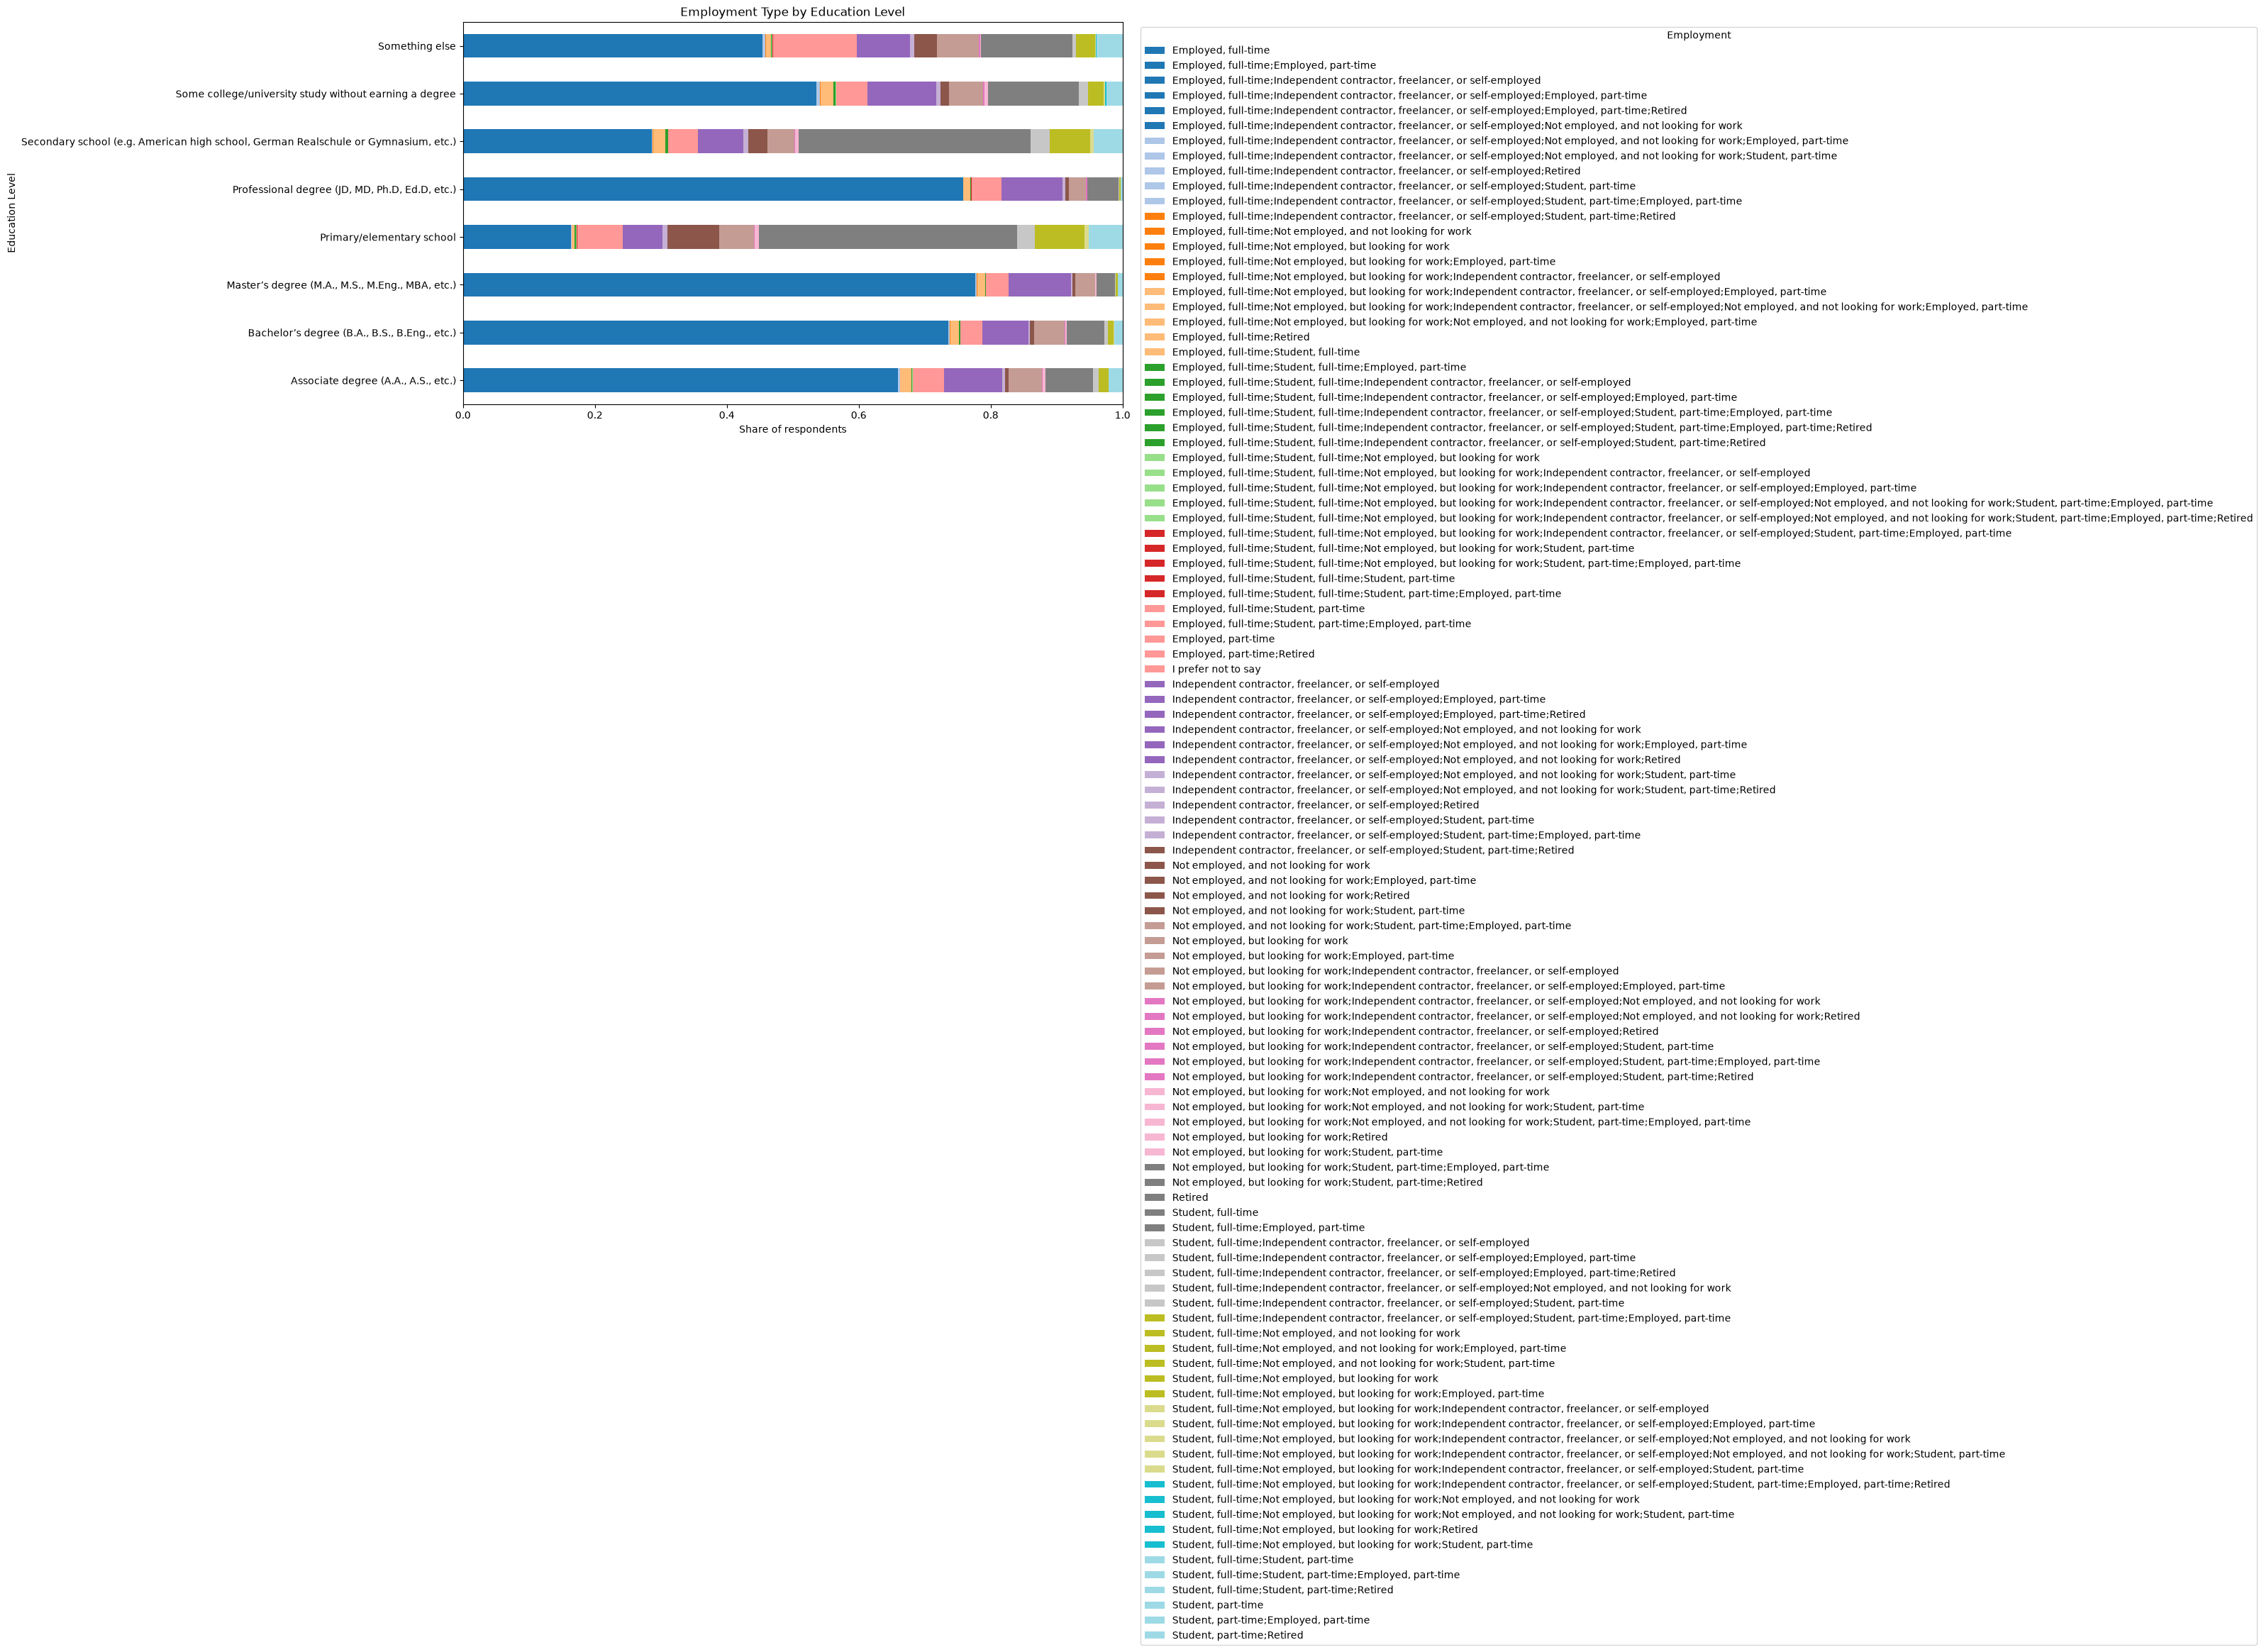

In [22]:
## Write your code here
education_employment=pd.crosstab(df_clean['EdLevel'], df_clean['Employment'], normalize='index') # normalize='index' computes the proportion of each employment type within each education level
print(education_employment.round(3))

top_education=df_clean['EdLevel'].value_counts().head(10).index
plot_table=education_employment.loc[education_employment.index.intersection(top_education)] #Filter the education_employment table to include only the top education categories
plot_table.plot(kind='barh',stacked=True,figsize=(12,7),colormap='tab20')
plt.title('Employment Type by Education Level')
plt.xlabel('Share of respondents')
plt.ylabel('Education Level')
plt.legend(title='Employment',bbox_to_anchor=(1.02,1),loc='upper left')
plt.tight_layout()
plt.show()

### Step 10: Export Cleaned Data


- Save the cleaned dataset to a new CSV file for further use or sharing.


In [23]:
## Write your code here
# Save the cleaned and analyzed dataset
output_file = 'survey-data-eda-distribution-cleaned.csv'
df_clean.to_csv(output_file, index=False)
print(f'Dataset saved to: {output_file}')
print(f'Final dataset shape: {df_clean.shape}')

Dataset saved to: survey-data-eda-distribution-cleaned.csv
Final dataset shape: (65437, 114)


### Summary:


In this lab, you practiced key skills in exploratory data analysis, including:


- Examining the structure and content of the Stack Overflow survey dataset to understand its variables and data types.

- Identifying and addressing missing data to ensure the dataset's quality and completeness.

- Summarizing and visualizing key variables such as job satisfaction, programming languages, and remote work trends.

- Analyzing relationships in the data using techniques like:
    - Comparing programming languages respondents have worked with versus those they want to work with.
      
    - Exploring remote work preferences by region.

- Investigating correlations between professional coding experience and job satisfaction.

- Performing cross-tabulations to analyze relationships between employment status and education levels.


## Authors:
Ayushi Jain


### Other Contributors:
Rav Ahuja
Lakshmi Holla
Malika


Copyright © IBM Corporation. All rights reserved.
